In [1]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.12.0+cu130
Torchvision: 0.27.0+cu130
CUDA available: True
GPU: NVIDIA GB10


# 01 — Computer Vision Fundamentals

## Project 02: Deep Learning for Satellite Image Classification

### Overview

This notebook introduces the fundamentals of computer vision
using NumPy, Matplotlib, and PyTorch.

We will investigate how images are represented numerically,
how pixel data is organized, and how images are prepared for
deep-learning models.

### Learning Objectives

1. Understand digital image representation.
2. Explore grayscale and RGB images.
3. Manipulate image data with NumPy.
4. Convert image arrays into PyTorch tensors.
5. Understand image tensor dimensions.
6. Normalize pixel values.
7. Visualize individual RGB channels.
8. Transfer image tensors to the GPU.

### Hardware

NVIDIA DGX Spark

### Project Context

This notebook is part of a larger project investigating
satellite image classification using deep learning.

Subsequent notebooks will explore convolution operations,
CNN architectures, transfer learning, and model evaluation.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch

In [3]:
# create small image

grayscale_image = np.array([
    [0, 50, 100],
    [75, 125, 175],
    [150, 200, 255]
], dtype=np.uint8)

print("Image shape:", grayscale_image.shape)
print("Data type:", grayscale_image.dtype)
print("Pixel values:\n", grayscale_image)

Image shape: (3, 3)
Data type: uint8
Pixel values:
 [[  0  50 100]
 [ 75 125 175]
 [150 200 255]]


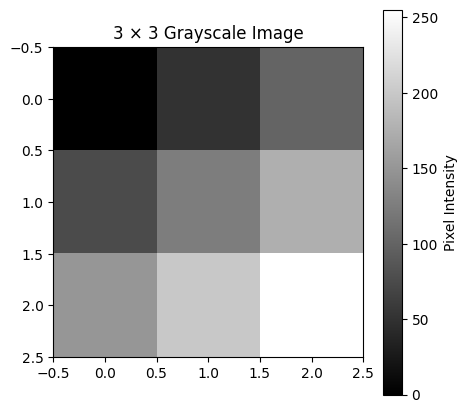

In [4]:
# visualize image

plt.figure(figsize=(5, 5))

plt.imshow(
    grayscale_image,
    cmap="gray",
    vmin=0,
    vmax=255
)

plt.title("3 × 3 Grayscale Image")
plt.colorbar(label="Pixel Intensity")
plt.show()

In [5]:
# create color image

rgb_image = np.zeros((100, 100, 3), dtype=np.uint8)

# Red channel
rgb_image[:, :, 0] = 255

print("Image shape:", rgb_image.shape)
print("Data type:", rgb_image.dtype)

Image shape: (100, 100, 3)
Data type: uint8


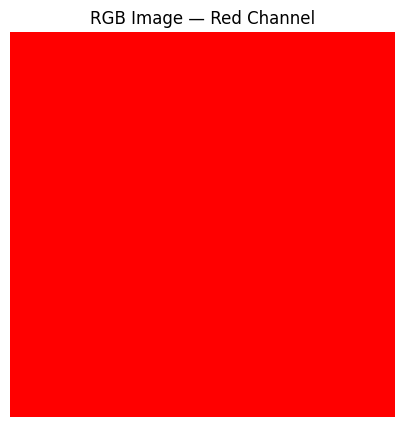

In [6]:
plt.figure(figsize=(5, 5))
plt.imshow(rgb_image)
plt.title("RGB Image — Red Channel")
plt.axis("off")
plt.show()

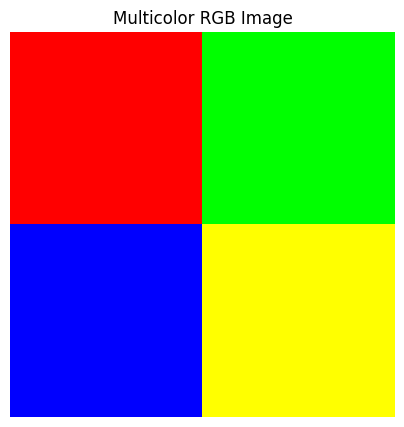

In [7]:
# multicolor image

image = np.zeros((100, 100, 3), dtype=np.uint8)

# Top-left: Red
image[:50, :50] = [255, 0, 0]

# Top-right: Green
image[:50, 50:] = [0, 255, 0]

# Bottom-left: Blue
image[50:, :50] = [0, 0, 255]

# Bottom-right: Yellow
image[50:, 50:] = [255, 255, 0]

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title("Multicolor RGB Image")
plt.axis("off")
plt.show()

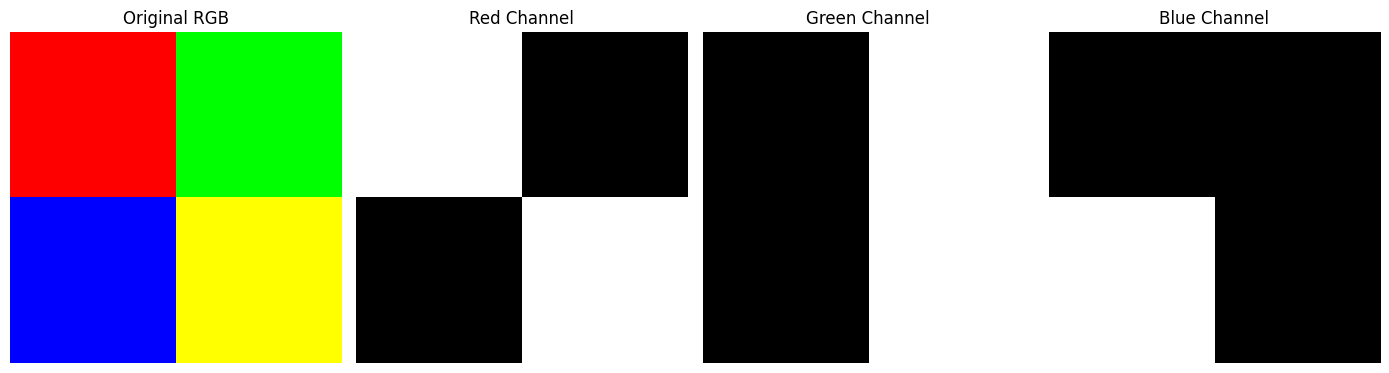

In [8]:
# extract rgb channels

red_channel = image[:, :, 0]
green_channel = image[:, :, 1]
blue_channel = image[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

axes[0].imshow(image)
axes[0].set_title("Original RGB")

axes[1].imshow(red_channel, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Red Channel")

axes[2].imshow(green_channel, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Green Channel")

axes[3].imshow(blue_channel, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Blue Channel")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
# above

# The grayscale channel images represent the intensity of each color component.

# For example, the red channel displays white wherever red has an intensity of 255.

# It displays black wherever red has an intensity of zero.

# Notice that yellow contributes to both the red and green channels.

# This illustrates how an RGB image combines numerical information from three separate channels.

In [10]:
# converting numpy channels to torch channels

image_tensor = torch.from_numpy(image.copy())

print("Original shape:", image_tensor.shape)

image_tensor = image_tensor.permute(2, 0, 1)

print("PyTorch shape:", image_tensor.shape)

Original shape: torch.Size([100, 100, 3])
PyTorch shape: torch.Size([3, 100, 100])


In [11]:
# normalizing the pixels and the image

normalized_tensor = image_tensor.float() / 255.0

print("Original dtype:", image_tensor.dtype)
print("Normalized dtype:", normalized_tensor.dtype)

print("Original range:")
print(image_tensor.min().item(), image_tensor.max().item())

print("Normalized range:")
print(normalized_tensor.min().item(), normalized_tensor.max().item())

Original dtype: torch.uint8
Normalized dtype: torch.float32
Original range:
0 255
Normalized range:
0.0 1.0


In [12]:
# Neural networks generally train more effectively when their numerical inputs are on an appropriate scale.

# Large differences in input magnitudes can complicate optimization.

# By scaling pixel intensities to a consistent range, we make them easier to process during training.

# Important distinction: Scaling to \([0,1]\) is only one form of normalization.

# Later, when using pretrained models, we'll often apply channel-specific normalization using means and standard deviations

In [13]:
# adding batch dimension

batch_tensor = normalized_tensor.unsqueeze(0)

print("Single image:", normalized_tensor.shape)
print("Batched image:", batch_tensor.shape)

Single image: torch.Size([3, 100, 100])
Batched image: torch.Size([1, 3, 100, 100])


In [14]:
# gpu tensor operations

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Selected device: cuda
GPU: NVIDIA GB10


In [15]:
# moving image tensor to gpu

gpu_image = batch_tensor.to(device)

print("Tensor device:", gpu_image.device)
print("Tensor shape:", gpu_image.shape)
print("Tensor dtype:", gpu_image.dtype)

Tensor device: cuda:0
Tensor shape: torch.Size([1, 3, 100, 100])
Tensor dtype: torch.float32


In [16]:
# performing a simple operation on the GPU

mean_pixel_value = gpu_image.mean()

print("Mean pixel value:", mean_pixel_value.item())

Mean pixel value: 0.4166666567325592


In [18]:
# calculate the mean pixel value for each channel

# (batch, height, width)

channel_means = gpu_image.mean(dim=(0, 2, 3))

print("Channel means:", channel_means.cpu().numpy())

Channel means: [0.5  0.5  0.25]


In [20]:
# inspecting a satellite sized image

torch.manual_seed(42)

images = torch.rand(16, 3, 64, 64) # 16 random images, 3 channels, 64x64 pixels

print("Batch shape:", images.shape)
print("Data type:", images.dtype)
print("Minimum:", images.min().item())
print("Maximum:", images.max().item())

Batch shape: torch.Size([16, 3, 64, 64])
Data type: torch.float32
Minimum: 2.205371856689453e-06
Maximum: 0.9999874830245972


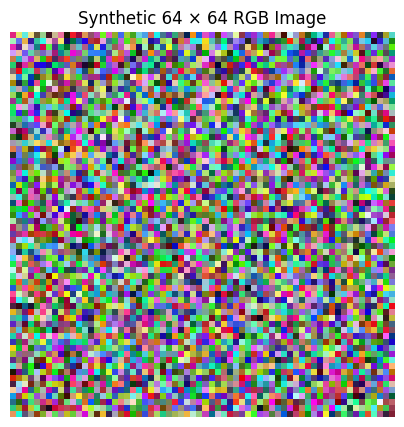

In [22]:
# Matplotlib expects channel-last image arrays
# we need to rearrange the axes again.

sample_image = images[0].permute(1, 2, 0)

plt.figure(figsize=(5, 5))
plt.imshow(sample_image)
plt.title("Synthetic 64 × 64 RGB Image")
plt.axis("off")
plt.show()

# image looks like random noise because it was generated randomly for practice.

## Summary

In this notebook, I explored the fundamentals of digital
image representation and image processing with NumPy and PyTorch.

### Concepts Covered

- Grayscale image representation
- RGB color channels
- Image array dimensions
- Pixel data types
- Image visualization
- NumPy-to-PyTorch conversion
- Channel-first tensor formatting
- Pixel normalization
- Batch dimensions
- GPU tensor operations

### Key Takeaways

Digital images are represented as numerical arrays.

RGB images contain three channels representing red, green,
and blue intensity values.

PyTorch convolutional neural networks typically process
image batches using the shape:

(N, C, H, W)

Image preprocessing commonly involves converting pixel
values into floating-point tensors and applying normalization.

GPU acceleration allows PyTorch to perform tensor operations
using NVIDIA CUDA.

### Next Steps

Notebook 02 will introduce convolution operations,
image filters, feature maps, and the mathematical
foundations of convolutional neural networks.